Mounting Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# Correct path to the zip file in Google Drive
zip_file_path = '/content/drive/MyDrive/archive.zip'

# Copy the zip file from Google Drive to the Colab working directory
!cp "{zip_file_path}" .

# Unzip the file quietly without listing all files
!unzip -q archive.zip


Importing LIbraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import pandas as pd
import wave
import sys
import os
import librosa
import librosa.display
import xgboost as xgb
from  sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
import sklearn.naive_bayes as nb
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier,GradientBoostingClassifier

from sklearn.neighbors import KDTree # KDTree is a class and should be capitalized
import seaborn as sn
from sklearn.metrics import confusion_matrix
from collections import Counter
from sklearn.datasets import make_classification
from imblearn.over_sampling import SMOTE # doctest: +NORMALIZE_WHITESPACE


Creating a Dataframe

In [ ]:
def create_dataframe(folder):
    soundwav = []
    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.endswith('.wav'):
                soundwav.append(file)
    data = [];

    for file in soundwav:
        if file[:3] not in data:
            data.append(file[:3])
    data = sorted(data)
    row =[]

    for i in data :
        r1=[]
        for file in soundwav:
            if file[:3]==i:
                r1.append(file)
        row.append(r1)


    df=pd.DataFrame(row,index=data)
    col = []
    for i in range(1,df.shape[1]+1):
        col.append('soundtrack-'+str(i))

    df.columns = col

    return df

In [ ]:
import pandas as pd
import os

# Define the folder path
folder = '/content/respiratory_sound_database/Respiratory_Sound_Database'
subfolder = os.path.join(folder, 'audio_and_txt_files/')

# Function to create DataFrame from audio files
def create_dataframe(subfolder):
    soundwav = []

    # Walk through the folder and collect .wav file names
    for root, dirs, files in os.walk(subfolder):
        for file in files:
            if file.endswith('.wav'):
                soundwav.append(file)

    # Extract unique patient IDs
    data = []
    for file in soundwav:
        if file[:3] not in data:  # Assuming patient ID is the first 3 characters
            data.append(file[:3])

    if not data:
        print("No data found. Check your folder path.")
        return None  # Return None if no data is found

    data = sorted(data)  # Sort the patient IDs

    # Create rows of sound files for each patient
    row = []
    for i in data:
        r1 = []
        for file in soundwav:
            if file[:3] == i:  # Group files by patient ID
                r1.append(file)
        row.append(r1)

    # Create DataFrame with patient IDs as index
    df = pd.DataFrame(row, index=data)

    # Set column names (soundtrack-1, soundtrack-2, ...)
    col = ['soundtrack-' + str(i+1) for i in range(df.shape[1])]
    df.columns = col

    return df  # Return the DataFrame

# Create DataFrame
df = create_dataframe(subfolder)

# Check if the DataFrame is empty and handle it
if df is None or df.empty:
    print("DataFrame is empty or None. Check the folder path and file names.")
else:
    df = df.rename_axis('ID')
    print(df.head(10))


                   soundtrack-1                soundtrack-2  \
ID                                                            
101  101_1b1_Al_sc_Meditron.wav  101_1b1_Pr_sc_Meditron.wav   
102  102_1b1_Ar_sc_Meditron.wav                        None   
103  103_2b2_Ar_mc_LittC2SE.wav                        None   
104  104_1b1_Ll_sc_Litt3200.wav  104_1b1_Lr_sc_Litt3200.wav   
105  105_1b1_Tc_sc_Meditron.wav                        None   
106  106_2b1_Pr_mc_LittC2SE.wav  106_2b1_Pl_mc_LittC2SE.wav   
107  107_3p2_Lr_mc_AKGC417L.wav  107_3p2_Ll_mc_AKGC417L.wav   
108  108_1b1_Al_sc_Meditron.wav                        None   
109  109_1b1_Ll_sc_Litt3200.wav  109_1b1_Lr_sc_Litt3200.wav   
110  110_1b1_Pr_sc_Meditron.wav  110_1p1_Lr_sc_Meditron.wav   

                   soundtrack-3                soundtrack-4  \
ID                                                            
101                        None                        None   
102                        None                       

Loading sound data

In [ ]:
import wave
import math
import scipy.io.wavfile as wf
import numpy as np
#wave file reader

#Will resample all files to the target sample rate and produce a 32bit float array
def read_wav_file(str_filename, target_rate):
    wav = wave.open(str_filename, mode = 'r')
    (sample_rate, data) = extract2FloatArr(wav,str_filename)

    if (sample_rate != target_rate):
        ( _ , data) = resample(sample_rate, data, target_rate)

    wav.close()
    return (target_rate, data.astype(np.float32))

def resample(current_rate, data, target_rate):
    x_original = np.linspace(0,100,len(data))
    x_resampled = np.linspace(0,100, int(len(data) * (target_rate / current_rate)))
    resampled = np.interp(x_resampled, x_original, data)
    return (target_rate, resampled.astype(np.float32))

# -> (sample_rate, data)
def extract2FloatArr(lp_wave, str_filename):
    (bps, channels) = bitrate_channels(lp_wave)

    if bps in [1,2,4]:
        (rate, data) = wf.read(str_filename)
        divisor_dict = {1:255, 2:32768}
        if bps in [1,2]:
            divisor = divisor_dict[bps]
            data = np.divide(data, float(divisor)) #clamp to [0.0,1.0]
        return (rate, data)

    elif bps == 3:
        #24bpp wave
        return read24bitwave(lp_wave)

    else:
        raise Exception('Unrecognized wave format: {} bytes per sample'.format(bps))

#Note: This function truncates the 24 bit samples to 16 bits of precision
#Reads a wave object returned by the wave.read() method
#Returns the sample rate, as well as the audio in the form of a 32 bit float numpy array
#(sample_rate:float, audio_data: float[])
def read24bitwave(lp_wave):
    nFrames = lp_wave.getnframes()
    buf = lp_wave.readframes(nFrames)
    reshaped = np.frombuffer(buf, np.int8).reshape(nFrames,-1)
    short_output = np.empty((nFrames, 2), dtype = np.int8)
    short_output[:,:] = reshaped[:, -2:]
    short_output = short_output.view(np.int16)
    return (lp_wave.getframerate(), np.divide(short_output, 32768).reshape(-1))  #return numpy array to save memory via array slicing

def bitrate_channels(lp_wave):
    bps = (lp_wave.getsampwidth() / lp_wave.getnchannels()) #bytes per sample
    return (bps, lp_wave.getnchannels())

In [ ]:
def load_sound_files(file_paths):
    raw_sounds = []
    raw_sr = []
    for fp in file_paths:
        sr,X = read_wav_file(fp,22000)
        #reduced_noise = nr.reduce_noise(audio_clip=X, noise_clip=X, verbose=False)# Visualize
        raw_sr.append(sr)
        raw_sounds.append(X)
    return raw_sounds,raw_sr

In [ ]:
def encode(line):
    if line[0]==0:
        if line[1]==0:
            return 0
        else:
            return 2
    if line[0]==1:
        if line[1]==0:
            return 1
        else:
            return 3

def frame(lengths):
    times=[]
    labels=[]
    for df in lengths:
        l=df.iloc[:,0:2]
        l=l.to_numpy();
        l=l.reshape(1,-1)
        l=np.ceil(l*22050)
        l=l.reshape(int(l.size/2),-1)
        times.append(l)
        # 0 present of crackle 1 present of wheeles 2 both
        #0 0 0 or 0 0 1 or 0 1 0 or 1 0 0
        k=df.iloc[:,2:4]
        k=k.to_numpy()
        z=[]
        for i in k:
            z.append(encode(i))
        z=np.asarray(z)
        z=z.reshape(-1,1)
        labels.append(z)
    return times,labels
def w_c_dataset(df,subfolder):
    files=[]
    lengths=[]
    for i,j in df.iterrows():
        for l in j:
            if(l!=None):
                files.append(subfolder+str(l))
                a=str(l).replace('.wav','.txt')
                tmp=pd.read_csv(subfolder+a,sep='\t',header = None)
                lengths.append(tmp)
                times,labels=frame(lengths)
    [sound,sr] = load_sound_files(files)
    return sound,sr,lengths,times,labels
def split_sounds(sounds,times,labels):
    s=[]
    l=[]
    for i,sound in enumerate(sounds):
        for t,label in zip(times[i],labels[i]):
            s.append(sound[int(t[0]):int(t[1])])
            if label==0:
                a=np.array([1,0,0,0])
            if label==1:
                a=np.array([0,1,0,0])
            if label==2:
                a=np.array([0,0,1,0])
            if label==3:
                a=np.array([0,0,0,1])
            l.append(a)
    return s,l

In [ ]:
[sound,sr,lengths,times,labels] = w_c_dataset(df,subfolder)
[data,label]=split_sounds(sound,times,labels)

Feature extraction

In [ ]:
import librosa
def extract_feature(X,sample_rate):

    n_fft=int(sample_rate*0.025)
    hop_length=int(sample_rate*0.01)

    mfcc = librosa.feature.mfcc(y=X, sr=sample_rate,n_fft=n_fft,hop_length=hop_length,
                                         n_mfcc=50)
    mean_mfcc = np.mean(mfcc.T,axis=0)
    std_mfcc = np.std(mfcc.T,axis=0)

    return np.vstack((mean_mfcc,std_mfcc))

In [ ]:
dataset = []
for d in data:
    a = extract_feature(d,sr[0])
    dataset.append(a)

data=np.asarray(dataset)
data = data.reshape([6898,data.shape[1]*data.shape[2],])

label=np.asarray(label)
a=np.zeros(label.shape[0])
for i in range(label.shape[0]):
    for j in range(label.shape[1]):
        if label[i][j]==1:
            a[i]=j

Scaling


In [ ]:
scaler=StandardScaler()
x_train,x_test,y_train,y_test = sklearn.model_selection.train_test_split(data,a,test_size=0.2, random_state=42,stratify=a)
scaler.fit(x_train)
x_train=scaler.transform(x_train)
x_test=scaler.transform(x_test)

In [ ]:
'''
    Cs = [2**(-2),2**(-1), 1,2**(1),2**(2),2**(3),2**(4),2**(5),2**(6),2**(7),2**(8),2**(9),2**(10)]
    gamma = [2**(-7),2**(-6),2**(-5),2**(-4),2**(-3),2**(-2),2**(-1),2**(0),2**(1),2**(2),2**(3)]


    param_grid = {'C': Cs,
                  'gamma': gamma,
                  'kernel': ['rbf'],
                  'decision_function_shape':['ovr'],
                  'class_weight': ['balanced']}
    grid1 = GridSearchCV(SVC(), param_grid,cv=3,n_jobs=-1, verbose = 3)

    # fitting the model for grid search
    grid1.fit(x_train, y_train)

    # print best parameter after tuning
    print(grid1.best_params_)
    # print how our model looks after hyper-parameter tuning
    print(grid1.best_estimator_)

    grid_predictions = grid1.predict(x_test)

    # print classification report
    print(classification_report(y_test, grid_predictions))
    print(accuracy_score(y_test,grid_predictions))

    print(sklearn.metrics.confusion_matrix(y_test,grid_predictions))
'''

"\n    Cs = [2**(-2),2**(-1), 1,2**(1),2**(2),2**(3),2**(4),2**(5),2**(6),2**(7),2**(8),2**(9),2**(10)]\n    gamma = [2**(-7),2**(-6),2**(-5),2**(-4),2**(-3),2**(-2),2**(-1),2**(0),2**(1),2**(2),2**(3)]\n\n\n    param_grid = {'C': Cs,\n                  'gamma': gamma,\n                  'kernel': ['rbf'],\n                  'decision_function_shape':['ovr'],\n                  'class_weight': ['balanced']}\n    grid1 = GridSearchCV(SVC(), param_grid,cv=3,n_jobs=-1, verbose = 3)\n\n    # fitting the model for grid search\n    grid1.fit(x_train, y_train)\n\n    # print best parameter after tuning\n    print(grid1.best_params_)\n    # print how our model looks after hyper-parameter tuning\n    print(grid1.best_estimator_)\n\n    grid_predictions = grid1.predict(x_test)\n\n    # print classification report\n    print(classification_report(y_test, grid_predictions))\n    print(accuracy_score(y_test,grid_predictions))\n\n    print(sklearn.metrics.confusion_matrix(y_test,grid_predictions))\n

SVM with best parameters

In [ ]:
# best parameters
#{'C': 4, 'class_weight': 'balanced', 'decision_function_shape': 'ovr', 'gamma': 0.03125, 'kernel': 'rbf'}

model = SVC(kernel='rbf',class_weight='balanced',gamma=0.03125,C=4)
model.fit(x_train,y_train)
y_pred = model.predict(x_test)
print(classification_report(y_test,y_pred))
print(accuracy_score(y_test,y_pred))

print(sklearn.metrics.confusion_matrix(y_test,y_pred))

              precision    recall  f1-score   support

         0.0       0.80      0.82      0.81       729
         1.0       0.68      0.76      0.72       373
         2.0       0.74      0.57      0.64       177
         3.0       0.70      0.56      0.62       101

    accuracy                           0.75      1380
   macro avg       0.73      0.68      0.70      1380
weighted avg       0.75      0.75      0.75      1380

0.7514492753623189
[[596 111  18   4]
 [ 75 283   4  11]
 [ 57   9 101  10]
 [ 17  13  14  57]]


In [ ]:

def onehenc(labels,classes=4):
    r=np.zeros((labels.shape[0],classes))
    for i in range(labels.shape[0]):
        for j in range(classes):
            if labels[i]==j:
                r[i,j]=1
    return r
def cm(y_test,y_pred):
    classes = ["normal", "crackles", "wheezes", "Wheezes&crackles"] # put your class labels
    df_cm = pd.DataFrame(confusion_matrix(y_test, y_pred,labels=range(4)), index = [i for i in classes],
                      columns = [i for i in classes])
    plt.figure(figsize = (10,7))
    plt.title('Confusion matrix')
    sn.heatmap(df_cm, annot=True,annot_kws={"size": 12},fmt='d')


    plt.show()

def plot_roc(y_test,y_pred):

    test=onehenc(y_test,4)
    pred=onehenc(y_pred,4)


    # Compute ROC curve and ROC area for each class
    from sklearn.metrics import roc_auc_score,roc_curve,auc
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    for i in range(4):
        fpr[i], tpr[i], _ = roc_curve(test[:, i], pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure()

    # Plot of a ROC curve for a specific class
    for i in range(4):
        plt.plot(fpr[i], tpr[i], label='ROC curve (area = %0.2f)' % roc_auc[i])
        plt.plot([0, 1], [0, 1], 'k--')
        plt.plot([1,0],[1,1])
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('Receiver operating characteristic example')
        plt.legend(loc="best")
        plt.show()

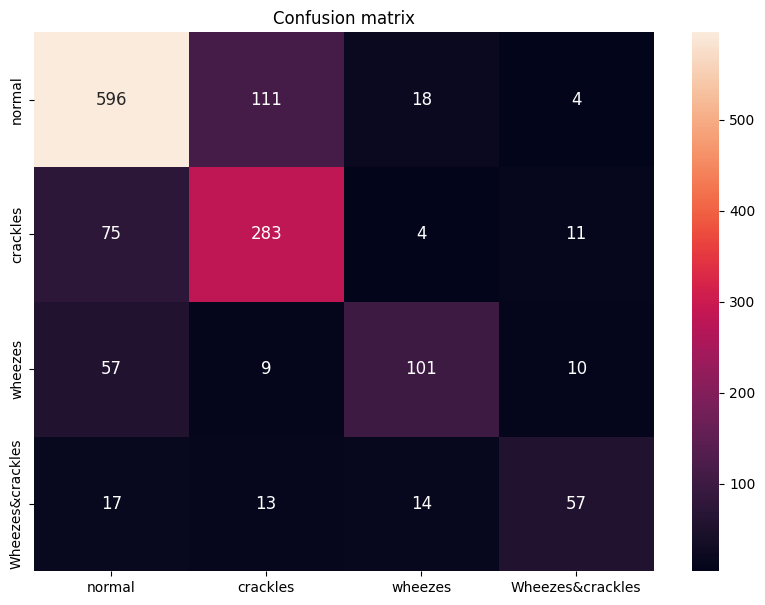

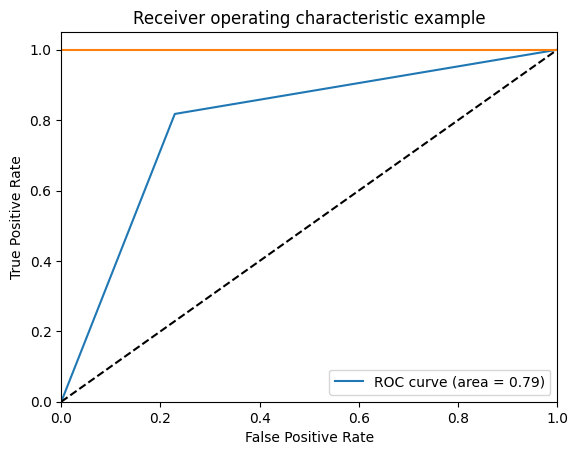

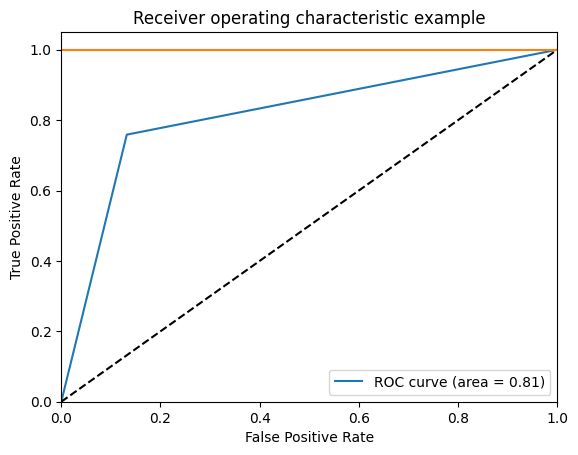

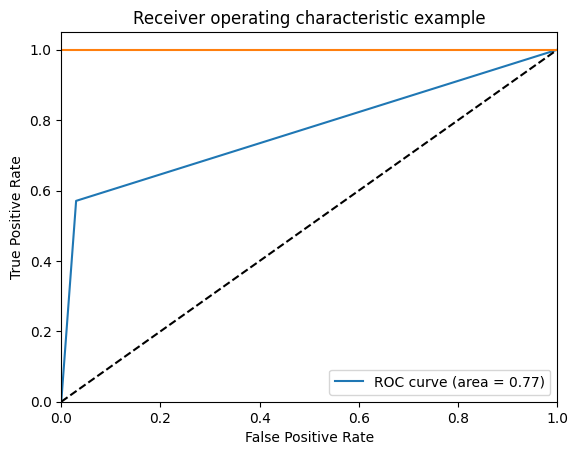

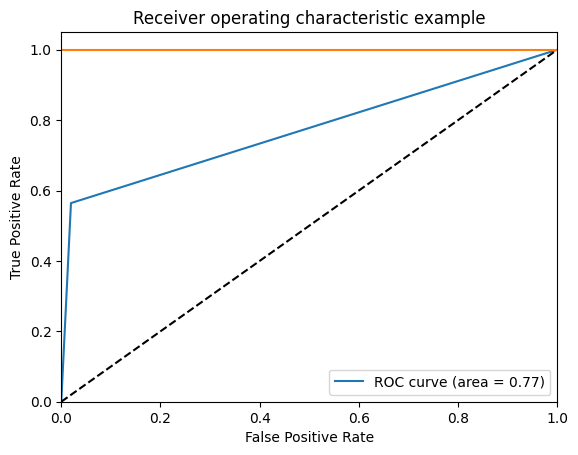

In [ ]:
cm(y_test,y_pred)
plot_roc(y_test,y_pred)

SVM with Smote

In [ ]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE
smote = SMOTE()
x_train, y_train = smote.fit_resample(x_train, y_train)

# Train and evaluate model as before
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Classification Report:
               precision    recall  f1-score   support

         0.0       0.79      0.84      0.81       729
         1.0       0.71      0.75      0.73       373
         2.0       0.74      0.58      0.65       177
         3.0       0.71      0.54      0.62       101

    accuracy                           0.76      1380
   macro avg       0.74      0.68      0.70      1380
weighted avg       0.76      0.76      0.76      1380

Accuracy Score: 0.7601449275362319
Confusion Matrix:
 [[611  95  17   6]
 [ 82 280   4   7]
 [ 58   7 103   9]
 [ 20  11  15  55]]


cross validation

In [ ]:
from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.model_selection import cross_val_score

# Apply SMOTE
smote = SMOTE()
x_train, y_train = smote.fit_resample(x_train, y_train)

# Check class distribution
print("Class distribution after SMOTE:", Counter(y_train))

# Train and evaluate model
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

# Evaluate the model
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Cross-validation
cv_scores = cross_val_score(model, x_train, y_train, cv=5, scoring='accuracy')
print("Cross-validation scores:", cv_scores)
print("Mean cross-validation score:", cv_scores.mean())


Class distribution after SMOTE: Counter({1.0: 2913, 0.0: 2913, 3.0: 2913, 2.0: 2913})
Classification Report:
               precision    recall  f1-score   support

         0.0       0.79      0.84      0.81       729
         1.0       0.71      0.75      0.73       373
         2.0       0.74      0.58      0.65       177
         3.0       0.71      0.54      0.62       101

    accuracy                           0.76      1380
   macro avg       0.74      0.68      0.70      1380
weighted avg       0.76      0.76      0.76      1380

Accuracy Score: 0.7601449275362319
Confusion Matrix:
 [[611  95  17   6]
 [ 82 280   4   7]
 [ 58   7 103   9]
 [ 20  11  15  55]]
Cross-validation scores: [0.91119691 0.92664093 0.93948498 0.95107296 0.96008584]
Mean cross-validation score: 0.9376963229323744


train and test models: SVM, RF, KNN, NAIVE BAIYES, XGBOOST

In [ ]:
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import xgboost as xgb

# Split and preprocess data
x_train, x_test, y_train, y_test = train_test_split(data, a, test_size=0.2, random_state=42, stratify=a)
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

# Define models
models = {
    "SVC": SVC(kernel='rbf', class_weight='balanced', gamma=0.03125, C=4),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "XGBoost": xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss'),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

# Train and evaluate each model
for name, model in models.items():
    # Train the model
    model.fit(x_train, y_train)

    # Predict on the test set
    y_pred = model.predict(x_test)


    # Evaluate the model
    print(f"{name} Classification Report:\n", classification_report(y_test, y_pred))
    print(f"{name} Accuracy Score:", accuracy_score(y_test, y_pred))
    print(f"{name} Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("-" * 50)



SVC Classification Report:
               precision    recall  f1-score   support

         0.0       0.80      0.82      0.81       729
         1.0       0.68      0.76      0.72       373
         2.0       0.74      0.57      0.64       177
         3.0       0.70      0.56      0.62       101

    accuracy                           0.75      1380
   macro avg       0.73      0.68      0.70      1380
weighted avg       0.75      0.75      0.75      1380

SVC Accuracy Score: 0.7514492753623189
SVC Confusion Matrix:
 [[596 111  18   4]
 [ 75 283   4  11]
 [ 57   9 101  10]
 [ 17  13  14  57]]
--------------------------------------------------
Random Forest Classification Report:
               precision    recall  f1-score   support

         0.0       0.70      0.91      0.79       729
         1.0       0.69      0.61      0.65       373
         2.0       0.82      0.33      0.47       177
         3.0       0.72      0.23      0.35       101

    accuracy                         

/usr/local/lib/python3.10/dist-packages/xgboost/core.py:158: UserWarning: [04:01:44] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBoost Classification Report:
               precision    recall  f1-score   support

         0.0       0.76      0.88      0.81       729
         1.0       0.70      0.69      0.69       373
         2.0       0.72      0.50      0.59       177
         3.0       0.76      0.42      0.54       101

    accuracy                           0.74      1380
   macro avg       0.74      0.62      0.66      1380
weighted avg       0.74      0.74      0.73      1380

XGBoost Accuracy Score: 0.7420289855072464
XGBoost Confusion Matrix:
 [[638  75  16   0]
 [108 256   4   5]
 [ 64  17  88   8]
 [ 28  17  14  42]]
--------------------------------------------------
Decision Tree Classification Report:
               precision    recall  f1-score   support

         0.0       0.67      0.68      0.68       729
         1.0       0.48      0.46      0.47       373
         2.0       0.37      0.38      0.37       177
         3.0       0.23      0.23      0.23       101

    accuracy             

Gradientboosting classifier

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Initialize and train the Gradient Boosting model
gb_model = GradientBoostingClassifier()
gb_model.fit(x_train, y_train)
gb_y_pred = gb_model.predict(x_test)

print("Gradient Boosting Classification Report:\n", classification_report(y_test, gb_y_pred))
print("Gradient Boosting Accuracy Score:", accuracy_score(y_test, gb_y_pred))
print("Gradient Boosting Confusion Matrix:\n", confusion_matrix(y_test, gb_y_pred))


Gradient Boosting Classification Report:
               precision    recall  f1-score   support

         0.0       0.68      0.84      0.75       729
         1.0       0.58      0.57      0.57       373
         2.0       0.69      0.26      0.38       177
         3.0       0.62      0.21      0.31       101

    accuracy                           0.65      1380
   macro avg       0.64      0.47      0.50      1380
weighted avg       0.65      0.65      0.62      1380

Gradient Boosting Accuracy Score: 0.6485507246376812
Gradient Boosting Confusion Matrix:
 [[615 102  10   2]
 [155 213   1   4]
 [102  22  46   7]
 [ 38  32  10  21]]


KNN with best parameters

In [ ]:
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Split and preprocess data
x_train, x_test, y_train, y_test = train_test_split(data, a, test_size=0.2, random_state=42, stratify=a)
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

# Define parameter grid for KNN
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['minkowski', 'euclidean', 'manhattan']
}

# Initialize GridSearchCV for KNN
grid_search_knn = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=5, n_jobs=-1, scoring='accuracy')
grid_search_knn.fit(x_train, y_train)

# Best parameters and score
print("Best parameters for KNN:", grid_search_knn.best_params_)
print("Best score for KNN:", grid_search_knn.best_score_)

# Use the best estimator to predict
best_knn_model = grid_search_knn.best_estimator_
y_pred_knn = best_knn_model.predict(x_test)

# Evaluate the model
print("KNN with Best Params Classification Report:\n", classification_report(y_test, y_pred_knn))
print("KNN with Best Params Accuracy Score:", accuracy_score(y_test, y_pred_knn))
print("KNN with Best Params Confusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))


Best parameters for KNN: {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'distance'}
Best score for KNN: 0.7624170575636933
KNN with Best Params Classification Report:
               precision    recall  f1-score   support

         0.0       0.85      0.84      0.84       729
         1.0       0.72      0.80      0.76       373
         2.0       0.73      0.56      0.64       177
         3.0       0.65      0.67      0.66       101

    accuracy                           0.78      1380
   macro avg       0.74      0.72      0.72      1380
weighted avg       0.78      0.78      0.78      1380

KNN with Best Params Accuracy Score: 0.7818840579710145
KNN with Best Params Confusion Matrix:
 [[611  91  20   7]
 [ 56 300   6  11]
 [ 46  12 100  19]
 [  6  16  11  68]]


Hybrid of SVM and KNN

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from imblearn.over_sampling import SMOTE

# Split and preprocess data
x_train, x_test, y_train, y_test = train_test_split(data, a, test_size=0.2, random_state=42, stratify=a)
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

# Initialize and train SVM model with SMOTE
smote = SMOTE(random_state=42)
x_train_resampled, y_train_resampled = smote.fit_resample(x_train, y_train)
svm = SVC(kernel='rbf', class_weight='balanced', gamma=0.03125, C=4, probability=True)
svm.fit(x_train_resampled, y_train_resampled)

# Initialize and train KNN model
knn = KNeighborsClassifier(n_neighbors=3, weights='distance', metric='manhattan')
knn.fit(x_train, y_train)

# Make predictions on the test set
svm_pred_prob = svm.predict_proba(x_test)
knn_pred_prob = knn.predict_proba(x_test)

# Combine predictions for the meta-model
meta_features = np.hstack((svm_pred_prob, knn_pred_prob))

# Train meta-model (Logistic Regression)
meta_model = LogisticRegression()
meta_model.fit(meta_features, y_test)

# Make final predictions
final_predictions = meta_model.predict(meta_features)

# Evaluate the hybrid model
print("Hybrid Model Classification Report:\n", classification_report(y_test, final_predictions))
print("Hybrid Model Accuracy Score:", accuracy_score(y_test, final_predictions))
print("Hybrid Model Confusion Matrix:\n", confusion_matrix(y_test, final_predictions))


Hybrid Model Classification Report:
               precision    recall  f1-score   support

         0.0       0.82      0.88      0.85       729
         1.0       0.76      0.76      0.76       373
         2.0       0.78      0.60      0.68       177
         3.0       0.73      0.62      0.67       101

    accuracy                           0.80      1380
   macro avg       0.77      0.72      0.74      1380
weighted avg       0.79      0.80      0.79      1380

Hybrid Model Accuracy Score: 0.7956521739130434
Hybrid Model Confusion Matrix:
 [[644  69  13   3]
 [ 75 284   4  10]
 [ 52   8 107  10]
 [ 10  15  13  63]]


In [ ]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, precision_recall_fscore_support
# Confusion matrix
conf_matrix = confusion_matrix(y_test, final_predictions)
print("Confusion Matrix:\n", conf_matrix)
def calculate_specificity(conf_matrix):
    specificity_scores = []
    for i in range(len(conf_matrix)):
        true_negatives = np.sum(np.delete(np.delete(conf_matrix, i, axis=0), i, axis=1))
        false_positives = np.sum(conf_matrix[:, i]) - conf_matrix[i, i]
        specificity = true_negatives / (true_negatives + false_positives)
        specificity_scores.append(specificity)
    return specificity_scores

specificity_scores = calculate_specificity(conf_matrix)
for i, spec in enumerate(specificity_scores):
    print(f"Specificity for class {i}: {spec:.4f}")

Confusion Matrix:
 [[644  69  13   3]
 [ 75 284   4  10]
 [ 52   8 107  10]
 [ 10  15  13  63]]
Specificity for class 0: 0.7896
Specificity for class 1: 0.9086
Specificity for class 2: 0.9751
Specificity for class 3: 0.9820


In [ ]:
# Calculate macro-average specificity (average of specificities across all classes)
macro_specificity = np.mean(specificity_scores)
print(f"Macro-Average Specificity of the model: {macro_specificity:.4f}")


Macro-Average Specificity of the model: 0.9138


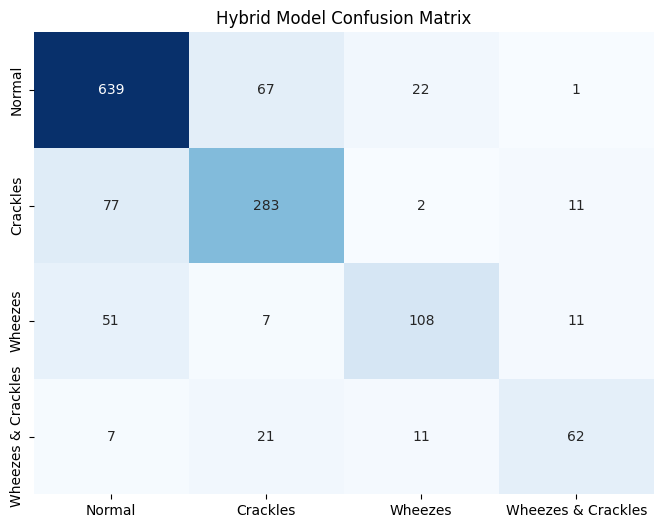

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion matrix data (from your example)
conf_matrix = np.array([[639, 67, 22, 1],
                        [77, 283, 2, 11],
                        [51, 7, 108, 11],
                        [7, 21, 11, 62]])
class_names = ['Normal', 'Crackles', 'Wheezes', 'Wheezes & Crackles']
# Plotting the confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(conf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False,xticklabels=class_names, yticklabels=class_names)
plt.title('Hybrid Model Confusion Matrix')
plt.show()


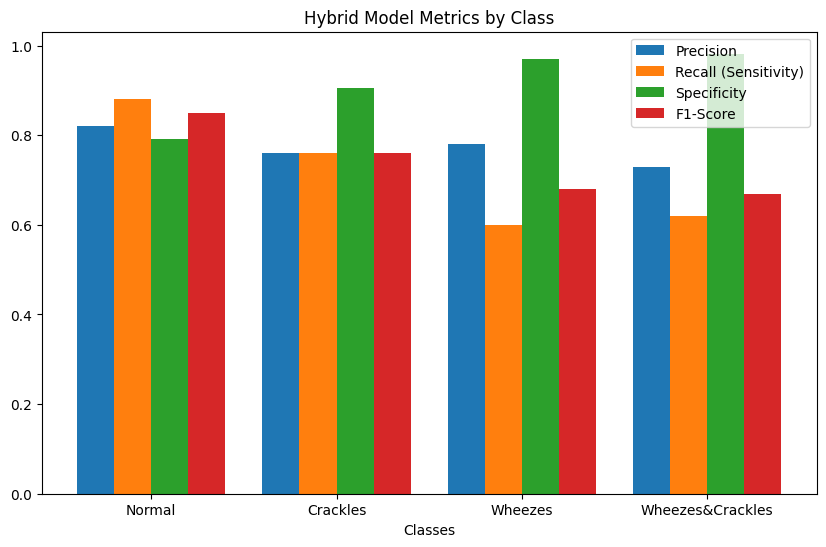

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data from the classification report (precision, recall, f1-score)
precision = [0.82, 0.76, 0.78, 0.73]
recall = [0.88, 0.76, 0.60, 0.62]  # Recall is equivalent to Sensitivity
f1_scores = [0.85, 0.76, 0.68, 0.67]

# Specificity calculation
def calculate_specificity(conf_matrix):
    specificity_scores = []
    for i in range(len(conf_matrix)):
        true_negatives = np.sum(np.delete(np.delete(conf_matrix, i, axis=0), i, axis=1))
        false_positives = np.sum(conf_matrix[:, i]) - conf_matrix[i, i]
        specificity = true_negatives / (true_negatives + false_positives)
        specificity_scores.append(specificity)
    return specificity_scores

specificity = calculate_specificity(conf_matrix)

# Labels for the x-axis
classes = ['Normal', 'Crackles', 'Wheezes', 'Wheezes&Crackles']

# Plotting the data
x = np.arange(len(classes))  # the label locations
width = 0.2  # the width of the bars

fig, ax = plt.subplots(figsize=(10,6))
rects1 = ax.bar(x - 1.5*width, precision, width, label='Precision')
rects2 = ax.bar(x - 0.5*width, recall, width, label='Recall (Sensitivity)')
rects3 = ax.bar(x + 0.5*width, specificity, width, label='Specificity')
rects4 = ax.bar(x + 1.5*width, f1_scores, width, label='F1-Score')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Classes')
ax.set_title('Hybrid Model Metrics by Class')
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.legend()

# Show the plot
plt.show()


hybrid of svm , knn, xgboost

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from imblearn.over_sampling import SMOTE
import xgboost as xgb

# Split and preprocess data
x_train, x_test, y_train, y_test = train_test_split(data, a, test_size=0.2, random_state=42, stratify=a)
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

# Initialize and train SVM model with SMOTE
smote = SMOTE(random_state=42)
x_train_resampled, y_train_resampled = smote.fit_resample(x_train, y_train)
svm = SVC(kernel='rbf', class_weight='balanced', gamma=0.03125, C=4, probability=True)
svm.fit(x_train_resampled, y_train_resampled)

# Initialize and train KNN model
knn = KNeighborsClassifier(n_neighbors=3, weights='distance', metric='manhattan')
knn.fit(x_train, y_train)

# Initialize and train XGBoost model
xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
xgb_model.fit(x_train, y_train)

# Make predictions on the test set for all models
svm_pred_prob = svm.predict_proba(x_test)
knn_pred_prob = knn.predict_proba(x_test)
xgb_pred_prob = xgb_model.predict_proba(x_test)

# Combine predictions for the meta-model
meta_features = np.hstack((svm_pred_prob, knn_pred_prob, xgb_pred_prob))

# Train meta-model (Logistic Regression)
meta_model = LogisticRegression()
meta_model.fit(meta_features, y_test)

# Make final predictions
final_predictions = meta_model.predict(meta_features)

# Evaluate the hybrid model
print("Hybrid Model Classification Report:\n", classification_report(y_test, final_predictions))
print("Hybrid Model Accuracy Score:", accuracy_score(y_test, final_predictions))
print("Hybrid Model Confusion Matrix:\n", confusion_matrix(y_test, final_predictions))


/usr/local/lib/python3.10/dist-packages/xgboost/core.py:158: UserWarning: [04:14:35] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Hybrid Model Classification Report:
               precision    recall  f1-score   support

         0.0       0.82      0.88      0.85       729
         1.0       0.76      0.75      0.75       373
         2.0       0.75      0.62      0.67       177
         3.0       0.71      0.58      0.64       101

    accuracy                           0.79      1380
   macro avg       0.76      0.71      0.73      1380
weighted avg       0.79      0.79      0.79      1380

Hybrid Model Accuracy Score: 0.7898550724637681
Hybrid Model Confusion Matrix:
 [[641  70  16   2]
 [ 76 281   6  10]
 [ 50   6 109  12]
 [ 12  15  15  59]]


<ipython-input-36-cb396f53b903>:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Model', y='Accuracy', data=df_accuracy, palette=custom_colors)
<ipython-input-36-cb396f53b903>:26: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


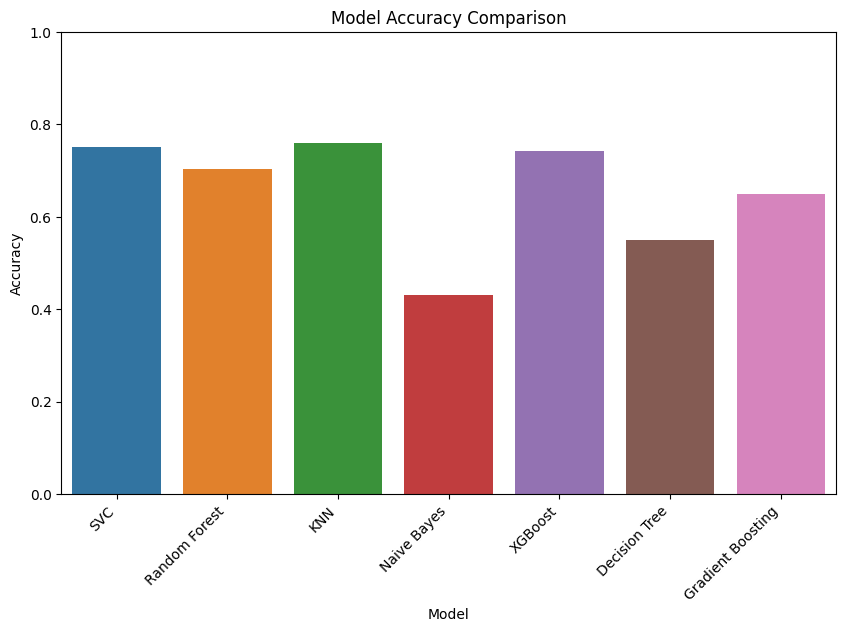

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Accuracy scores for each model
accuracy_scores = {
    'SVC': 0.7514,
    'Random Forest': 0.7036,
    'KNN': 0.7601,
    'Naive Bayes': 0.4304,
    'XGBoost': 0.7420,
    'Decision Tree': 0.5492,
    'Gradient Boosting': 0.6485
}

# Create a DataFrame
df_accuracy = pd.DataFrame(list(accuracy_scores.items()), columns=['Model', 'Accuracy'])

# Define custom colors
custom_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']

# Plot with custom colors
plt.figure(figsize=(10, 6))
ax = sns.barplot(x='Model', y='Accuracy', data=df_accuracy, palette=custom_colors)
ax.set_title('Model Accuracy Comparison')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.ylim(0, 1)  # Set the y-axis limit to 0-1 for accuracy
plt.show()
